---
title: "Wichtigste diskrete Verteilungen"
description: "Gleichverteilung, kategoriale, Bernoulli-, Binomial-, Poisson- und geometrische Verteilung in SciPy, mit Erwartungswert, Varianz, Entropie und der Frage, welches p zu den Daten passt."
---

[Vorlesungsaufzeichnung Entropie, zweiter Teil: diskrete Verteilungen (ab 1:07)](https://media.hhu.de/channel/video/data-science-vl-5-entropie-2024/8f216336cc82cdd8015ddb7a6c59c252/167?t=4020)

Wir haben inzwischen alle Werkzeuge beisammen, um uns einen Überblick über die wichtigsten
diskreten Verteilungen zu verschaffen: die pmf aus dem Kapitel
[Zufallsvariablen und Verteilungen](zufallsvariablen-verteilungen.md), Erwartungswert, Varianz und
Entropie aus dem Kapitel [Erwartungswert und Varianz](erwartungswert.md), und aus dem
Kapitel [Numpy](numpy.ipynb) das Handwerkszeug, um damit auch zu rechnen.

Jede Verteilung stellen wir im gleichen Format vor — Parameter, pmf, Erwartungswert, Varianz,
Entropie, Anwendungsbeispiele und der Name in `scipy.stats` — so wie wir es später auch für die
[stetigen Verteilungen](wichtigste-stetige-verteilungen.ipynb) tun werden.


## Konvention: diskrete Wahrscheinlichkeitsräume

In diesem Kapitel ist $\Omega$ stets *höchstens abzählbar*, meistens sogar endlich.
Dann ist die Potenzmenge $\mathcal{P}(\Omega)$ eine σ-Algebra, jede Teilmenge von $\Omega$ ist also
ein Ereignis, und das Wahrscheinlichkeitsmaß $P$ ist bereits vollständig festgelegt durch die Werte

$$
p(\omega) := P(\{\omega\})
$$

auf den einzelnen Ergebnissen — denn jedes Ereignis $A \subseteq \Omega$ ist die (höchstens abzählbare)
disjunkte Vereinigung seiner Elemente, also $P(A) = \sum_{\omega \in A} p(\omega)$.
Diese Funktion $p$ ist die *Wahrscheinlichkeitsmassefunktion* (pmf); ein anderer gebräuchlicher Name
ist *Zähldichte*. Alles, was wir über eine diskrete Verteilung wissen wollen, lässt sich aus ihr ablesen:

$$
\mathbb{E}(X) = \sum_{x} x\,p_X(x), \qquad
\mathbb{V}(X) = \mathbb{E}(X^2) - {\left(\mathbb{E}X\right)}^2, \qquad
H(X) = -\sum_{x} p_X(x)\log_2 p_X(x).
$$

```{admonition} Bemerkung
:class: note
Manche Quellen nennen die pmf im diskreten Fall auch *Verteilungsfunktion*. Diesen Namen verwenden
wir nicht, denn im Kapitel [Stetige Verteilungen](stetige-verteilungen.md) heißt die
*kumulative* Verteilungsfunktion $F(x) = P(X \leq x)$ so.
```


## Diskrete Verteilungen in SciPy

Genau wie für stetige Verteilungen stellt `scipy.stats` auch für diskrete Verteilungen Objekte bereit.
Der wichtigste Unterschied: Wo es bei stetigen Verteilungen eine Dichte `pdf` gibt, gibt es bei
diskreten Verteilungen eine pmf, und die heißt entsprechend `pmf`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st


def plotXdiskret(k, X, name, params):
    beschriftung = ", ".join(f"{wert}" for wert in params)
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    # Zuerst die Wahrscheinlichkeitsmassefunktion:
    axs[0].stem(k, X.pmf(k), basefmt=" ")
    axs[0].set_xlabel("$k$")
    axs[0].set_ylabel("$p(k) = P(X = k)$")
    axs[0].set_title(f"pmf von {name} mit {beschriftung}")
    # Dann die kumulative Verteilungsfunktion:
    axs[1].step(k, X.cdf(k), where="post")
    axs[1].set_xlabel("$k$")
    axs[1].set_ylabel("$F(k) = P(X \\leq k)$")
    axs[1].set_title(f"cdf von {name}")
    # tight_layout verhindert, dass sich die beiden Achsenbeschriftungen überlappen:
    plt.tight_layout()
    plt.show()


Die Methoden, die wir immer wieder brauchen, sind für alle Verteilungen dieselben.
Ist `X` eine diskrete Zufallsvariable aus `scipy.stats`, so gilt:

| gesucht | Aufruf |
|---|---|
| $P(X = k)$ | `X.pmf(k)` |
| $P(X \leq k)$ | `X.cdf(k)` |
| $P(X > k)$ | `X.sf(k)`, gleichbedeutend mit `1 - X.cdf(k)` |
| $P(X \geq k)$ | `X.sf(k-1)` |
| $P(X < k)$ | `X.cdf(k-1)` |
| eine Stichprobe der Größe $n$ | `X.rvs(size=n)` |
| $\mathbb{E}(X)$, $\mathbb{V}(X)$, $\sigma(X)$ | `X.mean()`, `X.var()`, `X.std()` |

Das `sf` steht für *survival function*, gelegentlich auch *Überlebensfunktion* genannt.

```{admonition} Achtung
:class: warning
Bei diskreten Verteilungen ist der Unterschied zwischen $\leq$ und $<$ nicht nur Kosmetik, denn
einzelne Werte haben echt positive Wahrscheinlichkeit. „Höchstens $k$“ heißt `X.cdf(k)`,
„weniger als $k$“ heißt `X.cdf(k-1)`, „mehr als $k$“ heißt `X.sf(k)` und „mindestens $k$“ heißt
`X.sf(k-1)`. Das ist die mit Abstand häufigste Fehlerquelle beim Rechnen mit diesen Verteilungen.
```


In [2]:
X = st.binom(10, 0.3)
print("P(X = 3)   =", X.pmf(3))
print("P(X <= 3)  =", X.cdf(3))
print("P(X > 3)   =", X.sf(3), "= 1 - P(X <= 3) =", 1 - X.cdf(3))
print("P(X >= 3)  =", X.sf(2))
assert np.isclose(X.cdf(3) + X.sf(3), 1.0)


P(X = 3)   = 0.2668279319999998
P(X <= 3)  = 0.6496107184000002
P(X > 3)   = 0.3503892815999998 = 1 - P(X <= 3) = 0.3503892815999998
P(X >= 3)  = 0.6172172136000003


## Diskrete Gleichverteilung

* Parameter $n$, Notation $\operatorname{Uni}\{1,\dots,n\}$
* pmf $p(k) = \dfrac{1}{n}$ für $k \in \{1,\dots,n\}$
* Erwartungswert $\dfrac{n+1}{2}$
* Varianz $\dfrac{n^2-1}{12}$
* Entropie $\log_2 n$ — das Maximum unter allen Verteilungen auf einer $n$-elementigen Menge
  (siehe [Erwartungswert und Varianz](erwartungswert.md), Abschnitt Entropie)
* Anwendungsbeispiele:
  * Der faire Würfel: $n=6$, also $\mathbb{E}(X) = 3{,}5$ und $\mathbb{V}(X) = \frac{35}{12} \approx 2{,}92$.
  * Ein idealisierter Zufallszahlengenerator, der ganze Zahlen in einem festen Bereich liefert.
* In `scipy.stats`: `st.randint(1, n+1)` — Achtung, die obere Grenze ist wie bei `range` **exklusiv**.

Den Erwartungswert kennen wir bereits. Die Varianz rechnen wir mit
$\mathbb{V}(X) = \mathbb{E}(X^2) - (\mathbb{E}X)^2$ aus. Mit der Summenformel
$\sum_{i=1}^n i^2 = \frac{n(n+1)(2n+1)}{6}$ ist

$$
\mathbb{E}(X^2) = \frac{1}{n}\sum_{i=1}^n i^2 = \frac{(n+1)(2n+1)}{6},
$$

und daher

$$
\mathbb{V}(X) = \frac{(n+1)(2n+1)}{6} - \frac{(n+1)^2}{4}
              = \frac{(n+1)\left( 2(2n+1) - 3(n+1) \right)}{12}
              = \frac{(n+1)(n-1)}{12}
              = \frac{n^2-1}{12}.
$$


E(X) = 3.5  erwartet: 3.5
V(X) = 2.9166666666666665  erwartet: 2.9166666666666665


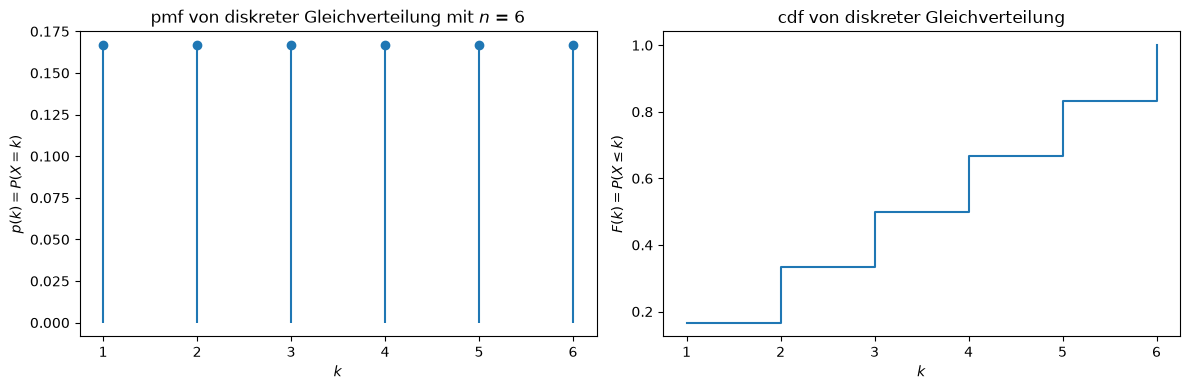

In [3]:
n = 6
X = st.randint(1, n + 1)   # obere Grenze exklusiv, also 1 bis 6
print("E(X) =", X.mean(), " erwartet:", (n + 1) / 2)
print("V(X) =", X.var(),  " erwartet:", (n**2 - 1) / 12)

plotXdiskret(np.arange(1, n + 1), X, "diskreter Gleichverteilung", (f"$n$ = {n}",))


## Kategoriale Verteilung

* Parameter ein Wahrscheinlichkeitsvektor $p = (p_1,\dots,p_n) \in \Delta_n$, also $p_i \geq 0$ und $\sum_i p_i = 1$
* pmf $p(\omega_i) = p_i$ auf einer $n$-elementigen Menge $\Omega = \{\omega_1,\dots,\omega_n\}$
* Erwartungswert (wenn wir $\omega_i$ mit der Zahl $i$ identifizieren) $\sum_{i=1}^n i\,p_i$ — im
  Allgemeinen nicht weiter vereinfachbar
* Varianz $\sum_{i=1}^n i^2 p_i - \left(\sum_{i=1}^n i\,p_i\right)^2$
* Entropie $-\sum_i p_i \log_2 p_i$
* Anwendungsbeispiele:
  * Eine Urne mit $m$ Bällen in $n$ Farben, davon $n_i$ Bälle der Farbe $i$; Ziehen **mit** Zurücklegen
    ergibt $p_i = \frac{n_i}{m}$.
  * Jede Umfrage mit einer festen Liste einander ausschließender Antwortmöglichkeiten.
* In `scipy.stats`: kein eigenes Objekt, aber `st.rv_discrete(values=(werte, p))` baut eines;
  zum bloßen Ziehen von Stichproben genügt `rng.choice(werte, p=p)` aus dem Kapitel [Numpy](numpy.ipynb).

Der Parameterraum ist genau das Simplex $\Delta_n$, das wir im Kapitel
[Zufallsvariablen und Verteilungen](zufallsvariablen-verteilungen.md) kennengelernt haben: Die
Gleichverteilung sitzt in seinem Mittelpunkt, die Dirac-Verteilungen in seinen Ecken. Die kategoriale
Verteilung ist damit die allgemeinste Verteilung auf einer endlichen Menge — alle folgenden Verteilungen
dieses Kapitels sind Spezialfälle oder Konstruktionen daraus. Auch das Beispiel mit den vier Pullover-Farben
aus jenem Kapitel ist eine kategoriale Verteilung mit $n=4$.

```{admonition} Bemerkung
:class: note
Im maschinellen Lernen taucht $\Delta_n$ als *Ausgaberaum* auf: Wenn ein Klassifikationsverfahren nicht
nur eine Klasse nennen, sondern seine Unsicherheit ausdrücken soll, gibt es einen Punkt in $\Delta_n$ aus,
also eine kategoriale Verteilung über die Klassen.
```


E(X) = 2.4  nachgerechnet: 2.4
V(X) = 0.6400000000000006
H(X) = 1.6854752972273344 bit
zum Vergleich, Gleichverteilung auf 4 Werten: 2.0 bit


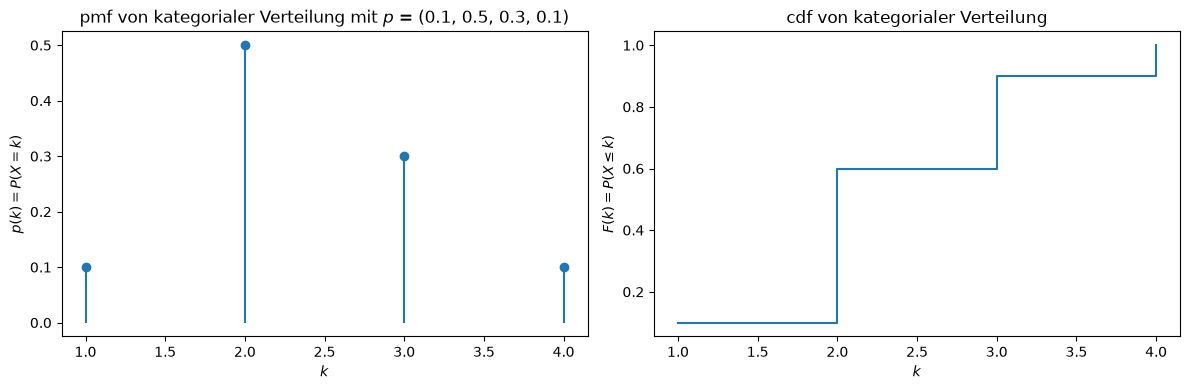

In [4]:
werte = np.arange(1, 5)
p = np.array([0.1, 0.5, 0.3, 0.1])
X = st.rv_discrete(values=(werte, p))

print("E(X) =", X.mean(), " nachgerechnet:", np.sum(werte * p))
print("V(X) =", X.var())
print("H(X) =", X.entropy() / np.log(2), "bit")   # scipy rechnet in nat
print("zum Vergleich, Gleichverteilung auf 4 Werten:", np.log2(4), "bit")

plotXdiskret(werte, X, "kategorialer Verteilung", (f"$p$ = {tuple(p.tolist())}",))


## Bernoulli-Verteilung

* Parameter $p \in [0,1]$, Notation $\operatorname{Ber}(p)$
* pmf $p(1) = p$ und $p(0) = 1-p$ auf $\Omega = \{0,1\}$
* Erwartungswert $p$
* Varianz $p(1-p)$
* Entropie $h(p) := -p\log_2 p - (1-p)\log_2(1-p)$, die *binäre Entropiefunktion*
* Anwendungsbeispiele:
  * Ein einzelner Münzwurf, auch mit unfairer Münze.
  * Jedes Ja/Nein-Merkmal: ein Bauteil ist defekt oder nicht, eine Mail ist Spam oder nicht.
* In `scipy.stats`: `st.bernoulli(p)`

Die Bernoulli-Verteilung ist der Spezialfall $n=2$ der kategorialen Verteilung und der einfachste
nichttriviale Fall überhaupt — sie hat **einen** Parameter. Erwartungswert und Varianz sind schnell
ausgerechnet: $\mathbb{E}(X) = 0\cdot(1-p) + 1\cdot p = p$, und da $X^2 = X$ gilt (denn $0^2=0$ und $1^2=1$),
ist auch $\mathbb{E}(X^2) = p$ und somit

$$
\mathbb{V}(X) = \mathbb{E}(X^2) - {\left(\mathbb{E}X\right)}^2 = p - p^2 = p(1-p).
$$

Die Varianz ist maximal bei $p = \frac12$ und verschwindet für $p \in \{0,1\}$ — dort ist das Ergebnis
ja auch gar nicht mehr zufällig.

Im Kapitel [Zufallsvariablen und Verteilungen](zufallsvariablen-verteilungen.md) haben wir aus Daten
bereits einen Wert $\hat\pi$ geschätzt, ohne den Namen zu nennen: Das war der Parameter einer
Bernoulli-Verteilung.


### Die binäre Entropiefunktion

Die Entropie einer Bernoulli-Verteilung als Funktion von $p$ ist interessant genug für einen eigenen Blick.
Wir leiten sie ab. Mit $\log_2 x = \frac{\ln x}{\ln 2}$ ist

$$
\frac{d}{dp}\left( -p\log_2 p \right) = -\log_2 p - \frac{1}{\ln 2},
\qquad
\frac{d}{dp}\left( -(1-p)\log_2(1-p) \right) = \log_2(1-p) + \frac{1}{\ln 2},
$$

die beiden Konstanten heben sich also weg und es bleibt

$$
h'(p) = \log_2(1-p) - \log_2 p = -\log_2\frac{p}{1-p}.
$$

Die einzige Nullstelle liegt bei $p = 1-p$, also bei $p = \frac12$: Der faire Münzwurf hat die maximale
Entropie, nämlich $h(\frac12) = 1$ bit. Das passt zur Gleichverteilung als Maximum-Entropie-Verteilung.

```{admonition} Ausblick
:class: tip
Der Ausdruck $\log_2\frac{p}{1-p}$, um den es hier geht, hat einen eigenen Namen: Der Bruch
$\frac{p}{1-p}$ heißt *Chance* (englisch *odds*) und sein Logarithmus heißt *Logit*. Die Ableitung
der binären Entropie ist also genau das Negative des Logits. Die Umkehrfunktion des Logits ist die
logistische Sigmoidfunktion, und die ist der Baustein, aus dem die *logistische Regression* und
damit auch das einzelne Neuron eines neuronalen Netzes gebaut sind. Wer nach dieser Vorlesung
*Einführung in Deep Learning* hört, begegnet dieser Kurve dort gleich wieder.
```


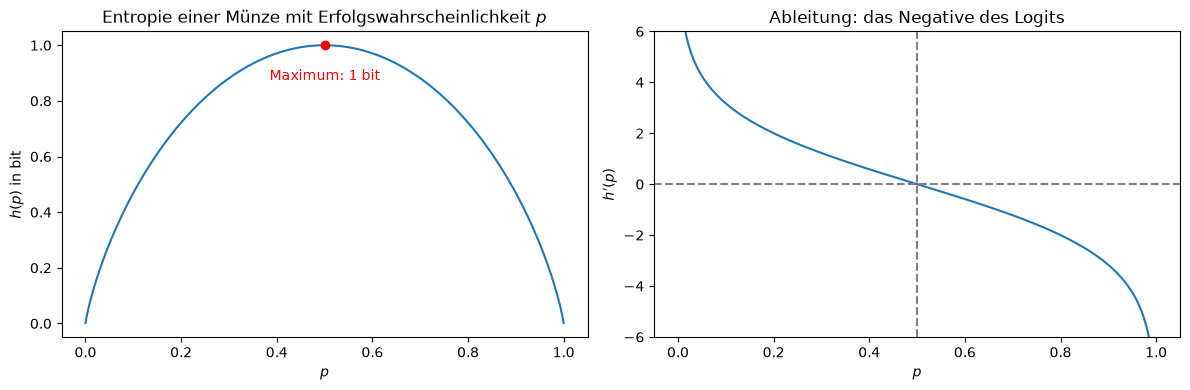

E(X) = 0.3  V(X) = 0.21  H(X) = 0.8812908992306927 bit


In [5]:
p = np.linspace(1e-4, 1 - 1e-4, 500)
h = -p * np.log2(p) - (1 - p) * np.log2(1 - p)
h_strich = -np.log2(p / (1 - p))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot(p, h)
axs[0].plot(0.5, 1.0, "o", color="red")
axs[0].annotate("Maximum: 1 bit", (0.5, 1.0), textcoords="offset points",
                xytext=(0, -25), ha="center", color="red")
axs[0].set_xlabel("$p$")
axs[0].set_ylabel("$h(p)$ in bit")
axs[0].set_title("Entropie einer Münze mit Erfolgswahrscheinlichkeit $p$")

axs[1].plot(p, h_strich)
axs[1].axhline(0, linestyle="--", color="gray")
axs[1].axvline(0.5, linestyle="--", color="gray")
axs[1].set_ylim(-6, 6)
axs[1].set_xlabel("$p$")
axs[1].set_ylabel("$h'(p)$")
axs[1].set_title("Ableitung: das Negative des Logits")

plt.tight_layout()
plt.show()

X = st.bernoulli(0.3)
print("E(X) =", X.mean(), " V(X) =", X.var(), " H(X) =", X.entropy() / np.log(2), "bit")


## Binomialverteilung

* Parameter $n \in \mathbb{N}$ und $p \in [0,1]$, Notation $\operatorname{Bin}(n,p)$
* pmf $p(k) = \dbinom{n}{k}p^k(1-p)^{n-k}$ für $k \in \{0,1,\dots,n\}$
* Erwartungswert $np$
* Varianz $np(1-p)$
* Entropie: kein handlicher geschlossener Ausdruck; sie ist kleiner als $\log_2(n+1)$, denn maximal
  wäre die Gleichverteilung auf $\{0,\dots,n\}$
* Anwendungsbeispiele:
  * $n$-mal dieselbe Münze werfen und die Anzahl der Köpfe zählen.
  * Eine Stichprobe von $n$ Bauteilen ziehen und die defekten zählen.
  * Urne mit zwei Farben, $N$ Bälle davon $n_1$ rote, $p = \frac{n_1}{N}$, $n$-mal ziehen **mit** Zurücklegen.
* In `scipy.stats`: `st.binom(n, p)`

Die Binomialverteilung entsteht aus der Bernoulli-Verteilung durch Wiederholung. Sind
$X_1,\dots,X_n$ **unabhängige** Zufallsvariablen mit $X_i \sim \operatorname{Ber}(p)$, so zählt

$$
X := \sum_{i=1}^n X_i
$$

die Anzahl der Erfolge, und es ist $X \sim \operatorname{Bin}(n,p)$. Sie hat also **zwei** Parameter.

Warum die pmf so aussieht: Ein einzelnes festes Muster aus $k$ Erfolgen und $n-k$ Misserfolgen — etwa
$1,1,0,1,0,\dots$ — hat wegen der Unabhängigkeit die Wahrscheinlichkeit $p^k(1-p)^{n-k}$, unabhängig
davon, an welchen Stellen die Erfolge stehen. Und es gibt genau $\binom{n}{k}$ solche Muster, nämlich
so viele, wie es $k$-elementige Teilmengen von $\{1,\dots,n\}$ gibt. Aufsummieren liefert die Formel.

Erwartungswert und Varianz bekommen wir jetzt geschenkt. Der Erwartungswert folgt aus der Linearität:

$$
\mathbb{E}(X) = \sum_{i=1}^n \mathbb{E}(X_i) = n\,p.
$$

Für die Varianz brauchen wir die Unabhängigkeit — das ist genau die Rechenregel aus dem Abschnitt
[Rechenregeln für die Varianz](erwartungswert.md):

$$
\mathbb{V}(X) = \sum_{i=1}^n \mathbb{V}(X_i) = n\,p(1-p).
$$

Ohne Unabhängigkeit wäre das falsch. Man sieht hier gut, wozu diese Regel gut ist.


E(X) = 3.0  erwartet: 3.0
V(X) = 2.1  erwartet: 2.0999999999999996


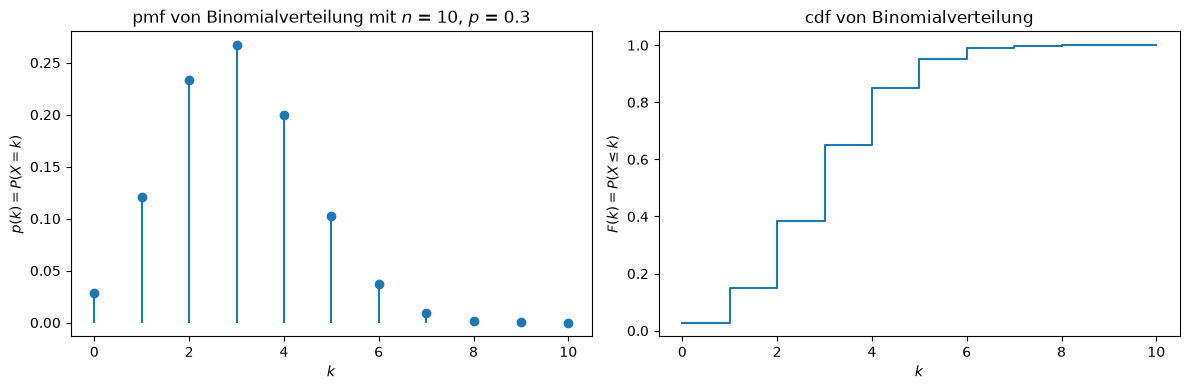

In [6]:
n, p = 10, 0.3
X = st.binom(n, p)
print("E(X) =", X.mean(), " erwartet:", n * p)
print("V(X) =", X.var(),  " erwartet:", n * p * (1 - p))

plotXdiskret(np.arange(0, n + 1), X, "Binomialverteilung", (f"$n$ = {n}", f"$p$ = {p}"))


### Welches p passt am besten zu den Daten?

Bisher haben wir $p$ als gegeben angesehen und nach der Wahrscheinlichkeit für $k$ Erfolge gefragt.
Jetzt drehen wir die Frage um: Wir haben $k = 3$ defekte Bauteile in einer Stichprobe von $n = 10$
gefunden und wollen wissen, welches $p$ zu dieser Beobachtung passt.

Die pmf gibt uns für **jedes** $p$ eine Wahrscheinlichkeit für genau diese Beobachtung:

$$
P(X = 3) = \binom{10}{3}p^3(1-p)^{7}.
$$

Vergleichen wir zwei Kandidaten, $p = 0{,}2$ und $p = 0{,}5$. Der Binomialkoeffizient ist in beiden
Fällen derselbe und kürzt sich weg, es genügt also, $p^3(1-p)^7$ zu vergleichen:

$$
0{,}2^3 \cdot 0{,}8^7 = 0{,}008 \cdot 0{,}2097\ldots \approx 0{,}00168,
\qquad
0{,}5^3 \cdot 0{,}5^7 = 0{,}5^{10} \approx 0{,}00098.
$$

Unsere Beobachtung ist unter $p = 0{,}2$ also etwa $1{,}7$-mal so wahrscheinlich wie unter $p = 0{,}5$.
In diesem Sinne passt $p = 0{,}2$ besser.

Damit liegt die Frage nahe, welches $p$ denn am allerbesten passt. Wir suchen also das Maximum von
$p \mapsto p^k(1-p)^{n-k}$ und leiten dazu ab:

$$
\frac{d}{dp}\left( p^k(1-p)^{n-k} \right)
 = k\,p^{k-1}(1-p)^{n-k} - (n-k)\,p^k(1-p)^{n-k-1}
 = p^{k-1}(1-p)^{n-k-1}\Big( k(1-p) - (n-k)p \Big).
$$

Für $0 < p < 1$ ist der vordere Faktor nicht null, es bleibt also die Bedingung $k(1-p) = (n-k)p$,
und die lösen wir auf: $k - kp = np - kp$, also $k = np$ und damit

$$
p = \frac{k}{n}.
$$

Für unsere Beobachtung ist das $p = \frac{3}{10} = 0{,}3$ — schlicht der Anteil der Erfolge in der
Stichprobe. Das ist genau das, was man ohne jede Rechnung geraten hätte; bemerkenswert ist, dass es
hier als Ergebnis einer Rechnung herauskommt, und zwar aus einem klar formulierten Kriterium:
Wähle den Parameter so, dass die tatsächliche Beobachtung möglichst wahrscheinlich wird.


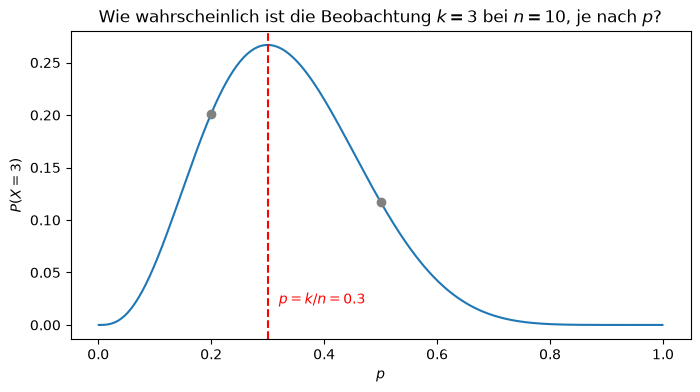

P(X=3) bei p=0.2: 0.20132659199999992
P(X=3) bei p=0.5: 0.1171875
P(X=3) bei p=0.3: 0.2668279319999998   <- das Maximum


In [7]:
k, n = 3, 10
p = np.linspace(0.001, 0.999, 500)
wahrscheinlichkeit = st.binom(n, p).pmf(k)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(p, wahrscheinlichkeit)
ax.axvline(k / n, linestyle="--", color="red")
ax.annotate(f"$p = k/n = {k/n}$", (k / n, 0.02), color="red",
            textcoords="offset points", xytext=(8, 0))
for kandidat in (0.2, 0.5):
    ax.plot(kandidat, st.binom(n, kandidat).pmf(k), "o", color="gray")
ax.set_xlabel("$p$")
ax.set_ylabel(f"$P(X = {k})$")
ax.set_title(f"Wie wahrscheinlich ist die Beobachtung $k={k}$ bei $n={n}$, je nach $p$?")
plt.show()

print("P(X=3) bei p=0.2:", st.binom(n, 0.2).pmf(k))
print("P(X=3) bei p=0.5:", st.binom(n, 0.5).pmf(k))
print("P(X=3) bei p=0.3:", st.binom(n, 0.3).pmf(k), "  <- das Maximum")


Dieses Vorgehen — den Parameter zu wählen, der die Beobachtung am wahrscheinlichsten macht —
heißt *Maximum-Likelihood-Schätzung*. Das Kapitel [Statistische Modelle](statistische-modelle.md)
behandelt sie allgemein und für andere Verteilungen.


## Exkurs: Poisson-Binomialverteilung

```{admonition} Hinweis
:class: note
Dieser Exkurs dient vornehmlich der Motivation der Poissonverteilung im nächsten Abschnitt und kann
beim ersten Lesen übersprungen werden.
```

* Parameter $p_1,\dots,p_n \in [0,1]$, eine Wahrscheinlichkeit je Versuch
* pmf $p(k) = \displaystyle\sum_{A \in F_k} \prod_{i \in A} p_i \prod_{i \notin A} (1-p_i)$,
  wobei $F_k$ die Menge der $k$-elementigen Teilmengen von $\{1,\dots,n\}$ ist
* Erwartungswert $\sum_{i=1}^n p_i$
* Varianz $\sum_{i=1}^n p_i(1-p_i)$
* Anwendungsbeispiel: $n$ Bauteile aus verschiedenen Chargen, jedes mit seiner eigenen
  Ausfallwahrscheinlichkeit — wie viele fallen aus?
* In `scipy.stats`: kein eigenes Objekt; die pmf lässt sich aber leicht selbst ausrechnen.

Wir werfen jetzt nicht mehr $n$-mal dieselbe Münze, sondern $n$ verschiedene Münzen, jede mit ihrer
eigenen Erfolgswahrscheinlichkeit $p_i$. Die $X_i \sim \operatorname{Ber}(p_i)$ sind weiterhin
unabhängig, nur eben nicht mehr identisch verteilt. Erwartungswert und Varianz folgen deshalb genau
wie bei der Binomialverteilung aus der Linearität und aus der Varianz-Regel für unabhängige Summanden;
für die Binomialverteilung sind alle $p_i$ gleich und wir erhalten $np$ bzw. $np(1-p)$ zurück.

Die pmf selbst ist unhandlich — die Summe läuft über $\binom{n}{k}$ Teilmengen. Praktisch rechnet man
sie iterativ aus: Man beginnt mit „null Münzen, null Erfolge mit Wahrscheinlichkeit 1“ und arbeitet
Münze für Münze ein.

Interessant wird der Fall vieler kleiner $p_i$. Setzen wir alle $p_i = \frac{\lambda}{n}$ und lassen
$n$ wachsen, so bleibt der Erwartungswert konstant bei $\lambda$, während jeder einzelne Versuch immer
unwahrscheinlicher wird. Das ist der Übergang zur Poissonverteilung:

```{admonition} Satz
Sei $\lambda > 0$ und $(p_n)_n$ eine Folge in $[0,1]$ mit $n\,p_n \to \lambda$ für $n \to \infty$.
Dann gilt für jedes feste $k \in \mathbb{N}_0$

$$
\lim_{n \to \infty} \binom{n}{k} p_n^k (1-p_n)^{n-k} = e^{-\lambda}\frac{\lambda^k}{k!}.
$$

**Ohne Beweis**
```


Summe der pmf = 1.0
E(X) = 1.9500000000000004  erwartet: 1.95
V(X) = 0.7174999999999998  erwartet: 0.7174999999999999


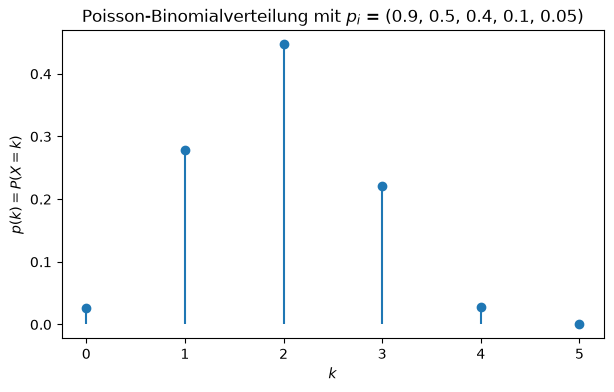

In [8]:
def poisson_binomial_pmf(ps):
    """pmf einer Poisson-Binomialverteilung, iterativ aufgebaut.

    Wir starten mit "null Münzen, null Erfolge" und arbeiten Münze für Münze ein:
    verteilung[k] ist die Wahrscheinlichkeit für k Erfolge bei den bisher betrachteten Münzen.
    """
    verteilung = np.array([1.0])
    for p in ps:
        ohne_erfolg = np.append(verteilung * (1 - p), 0.0)
        mit_erfolg = np.append(0.0, verteilung * p)
        verteilung = ohne_erfolg + mit_erfolg
    return verteilung


ps = np.array([0.9, 0.5, 0.4, 0.1, 0.05])
pmf = poisson_binomial_pmf(ps)
k = np.arange(len(pmf))

print("Summe der pmf =", pmf.sum())
print("E(X) =", np.sum(k * pmf), " erwartet:", ps.sum())
print("V(X) =", np.sum(k**2 * pmf) - np.sum(k * pmf) ** 2, " erwartet:", np.sum(ps * (1 - ps)))

fig, ax = plt.subplots(figsize=(7, 4))
ax.stem(k, pmf, basefmt=" ")
ax.set_xlabel("$k$")
ax.set_ylabel("$p(k) = P(X = k)$")
ax.set_title(f"Poisson-Binomialverteilung mit $p_i$ = {tuple(ps.tolist())}")
plt.show()


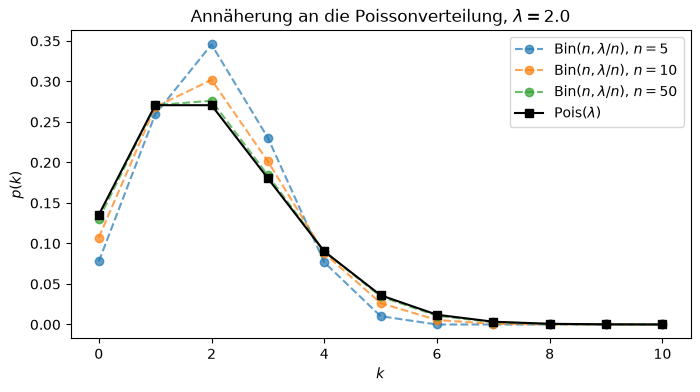

In [9]:
# Der Grenzuebergang: alle p_i gleich lambda/n, n waechst.
lam = 2.0
k = np.arange(0, 11)

fig, ax = plt.subplots(figsize=(8, 4))
for n in (5, 10, 50):
    ax.plot(k, st.binom(n, lam / n).pmf(k), "o--", alpha=0.7, label=f"$\\operatorname{{Bin}}(n, \\lambda/n)$, $n={n}$")
ax.plot(k, st.poisson(lam).pmf(k), "s-", color="black", label="$\\operatorname{Pois}(\\lambda)$")
ax.set_xlabel("$k$")
ax.set_ylabel("$p(k)$")
ax.set_title(f"Annäherung an die Poissonverteilung, $\\lambda = {lam}$")
ax.legend()
plt.show()


## Poissonverteilung

* Parameter $\lambda > 0$, Notation $\operatorname{Pois}(\lambda)$
* pmf $p(k) = e^{-\lambda}\dfrac{\lambda^k}{k!}$ für $k \in \mathbb{N}_0$
* Erwartungswert $\lambda$
* Varianz $\lambda$
* Anwendungsbeispiele:
  * Wie viele Anfragen erreichen den Server in einer Sekunde?
  * Wie viele Tippfehler stehen auf einer Seite?
  * Wie viele Atomkerne eines Präparats zerfallen in einer Minute?
* In `scipy.stats`: `st.poisson(mu=λ)`

Die Leitfrage lautet: Wie viele Ereignisse treten in einem festen Zeitraum ein, wenn sie unabhängig
voneinander und mit konstanter mittlerer Rate auftreten? Im Gegensatz zu allen bisherigen Verteilungen
dieses Kapitels ist der Träger nicht endlich — es könnten im Prinzip beliebig viele Ereignisse sein,
auch wenn große Anzahlen sehr unwahrscheinlich werden.

Dass sich die pmf zu $1$ aufsummiert, sieht man mit der Exponentialreihe
$\sum_{k \geq 0} \frac{\lambda^k}{k!} = e^{\lambda}$:

$$
\sum_{k=0}^\infty e^{-\lambda}\frac{\lambda^k}{k!} = e^{-\lambda}e^{\lambda} = 1.
$$

Der Erwartungswert folgt mit einer Indexverschiebung — der Summand für $k=0$ ist $0$ und fällt weg:

$$
\mathbb{E}(X) = \sum_{k=1}^\infty k\,e^{-\lambda}\frac{\lambda^k}{k!}
              = \lambda e^{-\lambda}\sum_{k=1}^\infty \frac{\lambda^{k-1}}{(k-1)!}
              = \lambda e^{-\lambda}e^{\lambda} = \lambda.
$$

Für die Varianz rechnet man genauso $\mathbb{E}(X(X-1)) = \lambda^2$ aus und erhält
$\mathbb{V}(X) = \mathbb{E}(X^2) - \lambda^2 = \lambda^2 + \lambda - \lambda^2 = \lambda$.
Erwartungswert und Varianz sind hier also gleich, was ein praktischer Test dafür ist, ob ein Datensatz
überhaupt zu einer Poissonverteilung passen kann.

```{admonition} Bemerkung
Zählt man Ereignisse mit $\operatorname{Pois}(\lambda)$ pro Zeiteinheit, so ist die *Wartezeit* bis zum
nächsten Ereignis $\operatorname{Exp}(\lambda)$-verteilt. Die Exponentialverteilung im Kapitel
[Wichtigste stetige Verteilungen](wichtigste-stetige-verteilungen.ipynb) beantwortet mit „Wie lange
dauert es, bis auf dem Server das nächste Paket ankommt?“ genau die stetige Kehrseite derselben Frage.
```


E(X) = 2.5  V(X) = 2.5  (beide gleich lambda)
P(X > 2) = 0.45618688411667035  von Hand: 0.4561868841166704


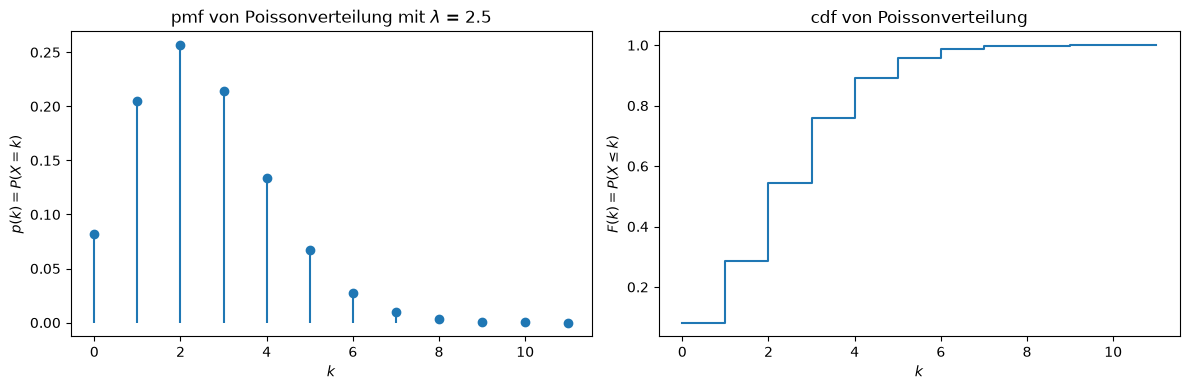

In [10]:
lam = 2.5
X = st.poisson(lam)
print("E(X) =", X.mean(), " V(X) =", X.var(), " (beide gleich lambda)")
print("P(X > 2) =", X.sf(2), " von Hand:", 1 - np.exp(-lam) * (1 + lam + lam**2 / 2))

plotXdiskret(np.arange(0, 12), X, "Poissonverteilung", (f"$\\lambda$ = {lam}",))


## Der Vollständigkeit halber: geometrische Verteilung

* Parameter $p \in (0,1]$, Notation $\operatorname{Geom}(p)$
* pmf $p(k) = (1-p)^{k-1}p$ für $k \in \{1,2,3,\dots\}$
* Erwartungswert $\dfrac{1}{p}$
* Varianz $\dfrac{1-p}{p^2}$
* Anwendungsbeispiele:
  * Wie oft muss ich würfeln, bis die erste Sechs fällt? ($p = \frac16$, im Mittel $6$ Würfe)
  * Wie viele Verbindungsversuche braucht es bis zum ersten Erfolg?
* In `scipy.stats`: `st.geom(p)`

Wir wiederholen ein Bernoulli-Experiment so lange, bis zum ersten Mal ein Erfolg eintritt, und zählen
die Versuche. Damit die ersten $k-1$ Versuche scheitern und der $k$-te gelingt, braucht es
$(1-p)^{k-1}p$ — daher die pmf.

Die geometrische Verteilung ist *gedächtnislos*: Hat man schon zehnmal vergeblich gewürfelt, ist die
Wahrscheinlichkeit, noch weitere $k$ Würfe zu brauchen, dieselbe wie am Anfang. Der Würfel erinnert
sich nicht. Damit ist sie das diskrete Gegenstück zur Exponentialverteilung, die im stetigen Fall die
einzige gedächtnislose Verteilung ist.

```{admonition} Achtung
:class: warning
Es gibt zwei gängige Konventionen: die Anzahl der **Versuche bis zum ersten Erfolg** (dann $k \geq 1$,
Erwartungswert $\frac1p$) und die Anzahl der **Fehlversuche davor** (dann $k \geq 0$, Erwartungswert
$\frac{1-p}{p}$). Wir verwenden die erste, `scipy.stats.geom` ebenfalls.
```


E(X) = 6.0  erwartet: 6.0
V(X) = 30.000000000000007  erwartet: 30.000000000000004


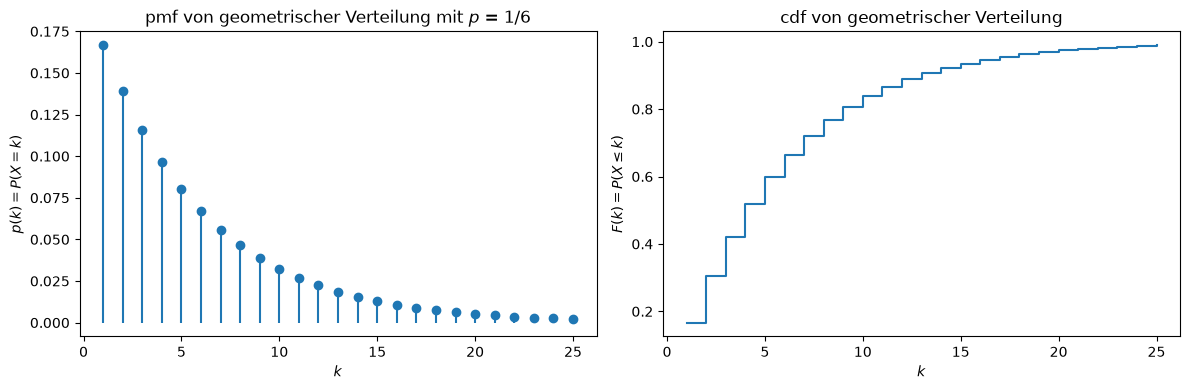

In [11]:
p = 1 / 6
X = st.geom(p)
print("E(X) =", X.mean(), " erwartet:", 1 / p)
print("V(X) =", X.var(),  " erwartet:", (1 - p) / p**2)

plotXdiskret(np.arange(1, 26), X, "geometrischer Verteilung", (f"$p$ = 1/6",))


## Rückblick

Alle Verteilungen dieses Kapitels hängen zusammen:

* Die **kategoriale Verteilung** ist die allgemeinste Verteilung auf einer endlichen Menge; ihr
  Parameterraum ist das Simplex $\Delta_n$.
* Die **diskrete Gleichverteilung** ist der Mittelpunkt dieses Simplex und hat maximale Entropie.
* Die **Bernoulli-Verteilung** ist der Fall $n=2$.
* Die **Binomialverteilung** zählt die Erfolge in $n$ unabhängigen Bernoulli-Versuchen mit gleichem $p$,
  die **Poisson-Binomialverteilung** erlaubt verschiedene $p_i$.
* Die **Poissonverteilung** ist deren Grenzfall für viele, jeweils sehr unwahrscheinliche Versuche.
* Die **geometrische Verteilung** dreht die Frage um: nicht wie viele Erfolge in fester Versuchszahl,
  sondern wie viele Versuche bis zum ersten Erfolg.

Im nächsten Schritt verlassen wir die abzählbaren Ergebnismengen. Wenn man die Binomialverteilung nicht
für kleine $p$, sondern für großes $n$ betrachtet, führt der Grenzübergang nicht zur Poissonverteilung,
sondern zur **Normalverteilung** — das ist der Satz von de Moivre-Laplace, mit dem das Kapitel
[Normalverteilung](normalverteilung.ipynb) beginnt.
